# Example 2.3 — Substructure search: how many quinazolines, and which are most potent?

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:14Z
- **Contents:** 1 exchange · 3 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/2.3-substructure-count-and-potency-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 2.3-substructure-count-and-potency-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 2.3-substructure-count-and-potency-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/2.3-substructure-count-and-potency-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 2.3-substructure-count-and-potency-notebook-rerun.ipynb 2.3-substructure-count-and-potency-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

How many compounds in BindingDB contain a quinazoline core, and which are the most potent?

In [ ]:
# Call 1 · substructure_search · ran 2026-11-24 04:55:12 UTC
await replay.call(1, 'substructure_search', {'query': 'c1ncnc2ccccc12', 'count_only': True},
                  sha256='ad912a70a253ee3780d7544aa8474e0eec511cb9332eb8f04475147b59b36718')

**Call 1** · `substructure_search` · recorded result · sha256 `ad912a70a253…`

| name | smiles |
| --- | --- |
| query | c1ccc2ncncc2c1 |

```json
{
  "query": {
    "input": "c1ncnc2ccccc12",
    "interpreted_as": "smiles",
    "canonical": "c1ccc2ncncc2c1"
  },
  "n_matching_compounds": 38987,
  "compounds_searched": 1466457,
  "compounds_indexed": 1466457
}
```


In [ ]:
# Call 2 · substructure_search · ran 2026-11-24 04:55:12 UTC
await replay.call(2, 'substructure_search', {'query': 'c1ncnc2ccccc12', 'max_value_nm': 0.1, 'limit': 15},
                  sha256='b177bd9c6812ce31ae2a3288c06a008b3e9b915587468078b96ebcb3ece443bb')

**Call 2** · `substructure_search` · recorded result · sha256 `b177bd9c6812…`

| name | smiles |
| --- | --- |
| query | c1ccc2ncncc2c1 |

```json
{
  "query": {
    "input": "c1ncnc2ccccc12",
    "interpreted_as": "smiles",
    "canonical": "c1ccc2ncncc2c1"
  },
  "compounds_searched": 22182,
  "search_set_size": 22182
}
```

_15 rows, truncated at the limit_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements | smiles |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50372858 | IC50 | = | 0.0039 | nM | 11.41 | 50102750 | CHEMBL3359091 | 1260 |  | Collagenase 3 | P45452 | Homo sapiens |  |  | ChEMBL\_1431418 (CHEMBL3388707) | 25264600 | 10.1021/jm500981k | 2014 | 0.43 | 8.09 |  | 2 | COc1cccc(c1)CNC(=O)C2=Nc3ccc(c(c3C(=O)N2)OCCc4ccc(cc4)C(=O)O)F |
| 50029862 | Ki | = | 0.006 | nM | 11.22 | 3032 | PD153035 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_473565 (CHEMBL940057) | 18077363 | 10.1073/pnas.0708800104 | 2007 | 0.7 | 7.07 |  | 10 | COc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OC |
| 51320965 | Kd | = | 0.0066 | nM | 11.18 | 50228403 | LINAGLIPTIN | 1234 |  | Dipeptidyl peptidase 4 | P27487 | Homo sapiens |  |  | ChEMBL\_1928893 (CHEMBL4432069) | 27438064 | 10.1021/acs.jmedchem.6b00475 | 2016 | 0.44 | 10.03 |  | 3 | CC#CCn1c(nc2n(C)c(=O)n(Cc3nc(C)c4ccccc4n3)c(=O)c12)N1CCC\[C@@H\](N)C1 |
| 157896 | Ki | = | 0.01 | nM | 11 | 29568 | PRAZOSIN | 6432 |  | Alpha-1A adrenergic receptor | P43140 | Rattus norvegicus |  |  |  | 2885412 |  | 1987 | 0.54 | 9.22 |  | 15 | COc1cc2c(cc1OC)nc(nc2N)N3CCN(CC3)C(=O)c4ccco4 |
| 1160927 | IC50 | = | 0.01 | nM | 11 | 112499 | DACOMITINIB | 1200 |  | Epidermal growth factor receptor \[1-18,20-1210\] | P00533\[1-18,20-1210\] | Homo sapiens |  |  | pEGFR assay | WO2022090481 |  | 2022 | 0.46 | 5.84 |  | 2 | COc1cc2c(cc1NC(=O)/C=C/CN3CCCCC3)c(ncn2)Nc4ccc(c(c4)Cl)F |
| 51352937 | IC50 | = | 0.01 | nM | 11 | 50322823 | AFATINIB | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2017352 (CHEMBL4670930) | 32931277 | 10.1021/acs.jmedchem.0c00870 | 2020 | 0.44 | 6.61 |  | 7 | CN(C)C/C=C/C(=O)Nc1cc2c(cc1O\[C@H\]3CCOC3)ncnc2Nc4ccc(c(c4)Cl)F |
| 51528512 | IC50 | = | 0.029 | nM | 10.54 | 5446 | Tarceva | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2299669 | 37197473 | 10.1021/acsmedchemlett.2c00514 | 2023 | 0.5 | 7.13 |  | 7 | COCCOc1cc2c(cc1OCCOC)ncnc2Nc3cccc(c3)C#C |
| 51493732 | IC50 | = | 0.04 | nM | 10.4 | 50595124 | Zactima | 692 |  | Vascular endothelial growth factor receptor 2 | P35968 | Homo sapiens |  |  | ChEMBL\_2238015 (CHEMBL5151911) | 34402300 | 10.1021/acs.jmedchem.0c02167 | 2021 | 0.47 | 5.97 |  | 1 | COc1cc2/c(=N/c3ccc(Br)cc3F)nc\[nH\]c2cc1OCC1CCN(C)CC1 |
| 51505087 | Ki | = | 0.04 | nM | 10.4 | 18268 | TMQ | 1875 |  | Dihydrofolate reductase | P00374 | Homo sapiens |  |  | ChEMBL\_2260222 (CHEMBL5215233) | 33243532 | 10.1016/j.ejmech.2020.113016 | 2021 | 0.53 | 7.66 | anil\_di\_alk\_C(246) | 2 | COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC |
| 51352944 | IC50 | = | 0.06 | nM | 10.22 | 5445 | Tykerb | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2017353 (CHEMBL4670931) | 32931277 | 10.1021/acs.jmedchem.0c00870 | 2020 | 0.35 | 4.08 |  | 2 | CS(=O)(=O)CCNCc1ccc(o1)-c1ccc2ncnc(Nc3ccc(OCc4cccc(F)c4)c(Cl)c3)c2c1 |
| 51525814 | IC50 | = | 0.061 | nM | 10.21 | 50468247 | Poziotinib | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2294498 | 36804726 | 10.1016/j.bmc.2023.117202 | 2023 | 0.42 | 4.83 |  | 3 | COc1cc2ncnc(Nc3ccc(Cl)c(Cl)c3F)c2cc1OC1CCN(CC1)C(=O)C=C |
| 51464906 | Kd | = | 0.077625 | nM | 10.11 | 50053929 | N-(9-Chloro-2-furan-2-yl-\[1,2,4\]triazolo\[1,5-c\]quinazolin-5-yl)-2-phenyl-acetamide | 2135 |  | Adenosine receptor A3 | P0DMS8 | Homo sapiens |  |  | ChEMBL\_2199491 (CHEMBL5112007) | 36173355 | 10.1021/acs.jmedchem.2c01123 | 2022 | 0.48 | 5.74 |  | 3 | Clc1ccc2nc(NC(=O)Cc3ccccc3)n3nc(nc3c2c1)-c1ccco1 |
| 57373 | IC50 | = | 0.08 | nM | 10.1 | 4567 | BMC163482 Compound 1 | 3945 |  | Epidermal growth factor receptor \[668-1210\] | P00533\[668-1210\] | Homo sapiens | 7.5 | 296.15 | EGFR IC50 Determination | 18316192 | 10.1016/j.bmc.2008.02.053 | 2008 | 0.6 | 5.84 |  | 1 | C=CC(=O)Nc1ccc2c(c1)c(ncn2)Nc3cccc(c3)Br |
| 50076446 | IC50 | = | 0.1 | nM | 10 | 5447 | Iressa | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_974507 (CHEMBL2412780) | 23792318 | 10.1016/j.ejmech.2013.05.026 | 2013 | 0.44 | 5.72 |  | 4 | COc1cc2c(cc1OCCCN3CCOCC3)c(ncn2)Nc4ccc(c(c4)Cl)F |
| 50189274 | Kd | = | 0.1 | nM | 10 | 4779 | Canertinib | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_774487 (CHEMBL1908704) | 22037378 | 10.1038/nbt.1990 | 2011 | 0.4 | 5.61 |  | 2 | C=CC(=O)Nc1cc2c(cc1OCCCN3CCOCC3)ncnc2Nc4ccc(c(c4)Cl)F |


In [ ]:
# Call 3 · run_sql · ran 2026-11-24 04:55:12 UTC
sql = """
    select a.monomerid, a.polymerid, a.affinity_type, count(*) n, median(a.value) med, min(a.value) best
    from activity a join (values (50102750,1260,'IC50'),(3032,520,'Ki'),(50228403,1234,'Kd'),(29568,6432,'Ki'),(112499,1200,'IC50'),(50322823,520,'IC50'),(5446,520,'IC50'),(50595124,692,'IC50'),(18268,1875,'Ki'),(5445,520,'IC50'),(50468247,520,'IC50'),(50053929,2135,'Kd'),(4567,3945,'IC50'),(5447,520,'IC50'),(4779,520,'Kd')) v(m,p,t)
    on a.monomerid=v.m and a.polymerid=v.p and a.affinity_type=v.t
    where a.relation='=' and a.unit='nM'
    group by 1,2,3 order by best
    
"""
await replay.call(3, 'run_sql', {'sql': sql},
                  sha256='6dae514a9cba43ffa61c03a6df1e3f52baa6626c2c4d24796a63ac6553be67a5')

**Call 3** · `run_sql` · recorded result · sha256 `6dae514a9cba…`

```json
{
  "order_warning": "Rows 4 and 5 tie on every ORDER BY column (best), so rows like them can swap places from run to run. End the ORDER BY with a unique column (e.g. monomerid; ki_result_id, affinity_type for measurements) so the result is the same on every run and a notebook's rerun check passes."
}
```

_15 rows_

| monomerid | polymerid | affinity_type | n | med | best |
| --- | --- | --- | --- | --- | --- |
| 50102750 | 1260 | IC50 | 3 | 0.0039 | 0.0039 |
| 3032 | 520 | Ki | 1 | 0.006 | 0.006 |
| 50228403 | 1234 | Kd | 2 | 2.6533 | 0.0066 |
| 112499 | 1200 | IC50 | 1 | 0.01 | 0.01 |
| 29568 | 6432 | Ki | 12 | 0.265 | 0.01 |
| 50322823 | 520 | IC50 | 102 | 1 | 0.01 |
| 5446 | 520 | IC50 | 173 | 30 | 0.029 |
| 50595124 | 692 | IC50 | 9 | 40 | 0.04 |
| 18268 | 1875 | Ki | 4 | 7.2 | 0.04 |
| 5445 | 520 | IC50 | 75 | 11 | 0.06 |
| 50468247 | 520 | IC50 | 16 | 0.266 | 0.061 |
| 50053929 | 2135 | Kd | 2 | 0.0876745 | 0.077625 |
| 4567 | 3945 | IC50 | 1 | 0.08 | 0.08 |
| 5447 | 520 | IC50 | 187 | 22 | 0.1 |
| 4779 | 520 | Kd | 32 | 0.205 | 0.1 |


**Figure 1: The most potent quinazolines in BindingDB.** _(as recorded)_

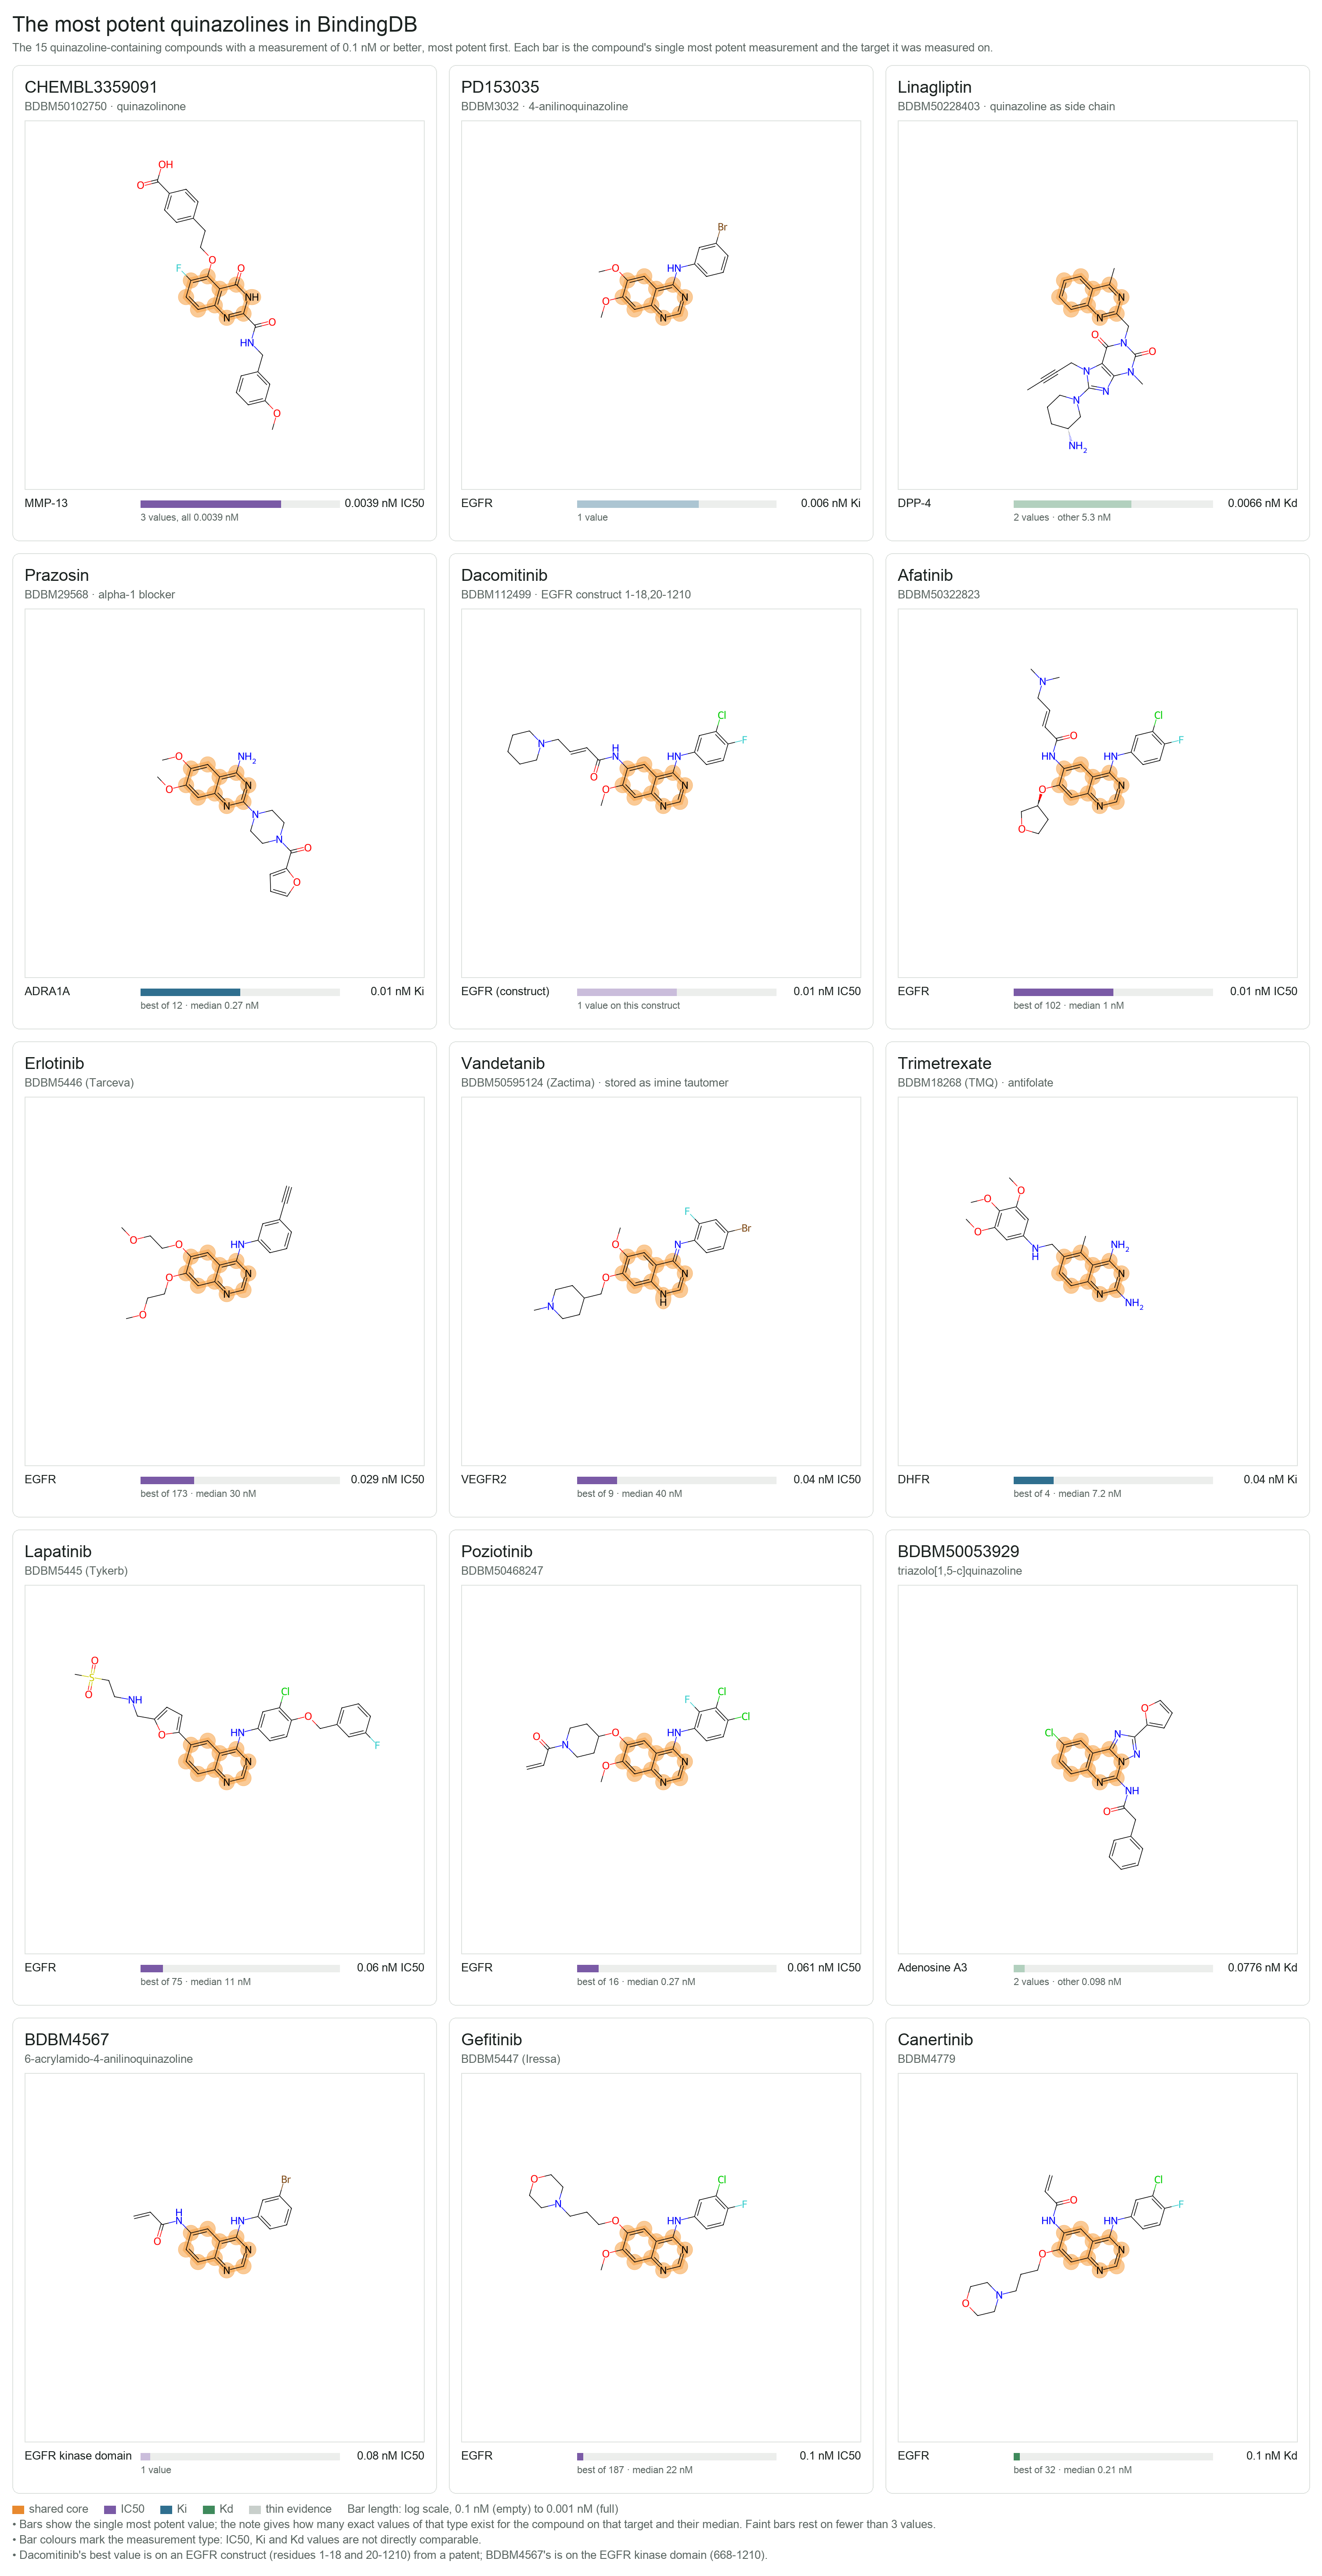

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'The most potent quinazolines in BindingDB',
    'compounds': [
        {
            'smiles': 'COc1cccc(c1)CNC(=O)C2=Nc3ccc(c(c3C(=O)N2)OCCc4ccc(cc4)C(=O)O)F',
            'title': 'CHEMBL3359091',
            'subtitle': 'BDBM50102750 · quinazolinone',
            'bars': [
                {'label': 'MMP-13', 'value_nm': 0.0039, 'type': 'IC50', 'note': '3 values, all 0.0039 nM'},
            ],
        },
        {
            'smiles': 'COc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OC',
            'title': 'PD153035',
            'subtitle': 'BDBM3032 · 4-anilinoquinazoline',
            'bars': [{'label': 'EGFR', 'value_nm': 0.006, 'type': 'Ki', 'note': '1 value', 'faint': True}],
        },
        {
            'smiles': 'CC#CCn1c(nc2n(C)c(=O)n(Cc3nc(C)c4ccccc4n3)c(=O)c12)N1CCC[C@@H](N)C1',
            'title': 'Linagliptin',
            'subtitle': 'BDBM50228403 · quinazoline as side chain',
            'bars': [
                {
                    'label': 'DPP-4',
                    'value_nm': 0.0066,
                    'type': 'Kd',
                    'note': '2 values · other 5.3 nM',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'COc1cc2c(cc1OC)nc(nc2N)N3CCN(CC3)C(=O)c4ccco4',
            'title': 'Prazosin',
            'subtitle': 'BDBM29568 · alpha-1 blocker',
            'bars': [
                {'label': 'ADRA1A', 'value_nm': 0.01, 'type': 'Ki', 'note': 'best of 12 · median 0.27 nM'},
            ],
        },
        {
            'smiles': 'COc1cc2c(cc1NC(=O)/C=C/CN3CCCCC3)c(ncn2)Nc4ccc(c(c4)Cl)F',
            'title': 'Dacomitinib',
            'subtitle': 'BDBM112499 · EGFR construct 1-18,20-1210',
            'bars': [
                {
                    'label': 'EGFR (construct)',
                    'value_nm': 0.01,
                    'type': 'IC50',
                    'note': '1 value on this construct',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CN(C)C/C=C/C(=O)Nc1cc2c(cc1O[C@H]3CCOC3)ncnc2Nc4ccc(c(c4)Cl)F',
            'title': 'Afatinib',
            'subtitle': 'BDBM50322823',
            'bars': [{'label': 'EGFR', 'value_nm': 0.01, 'type': 'IC50', 'note': 'best of 102 · median 1 nM'}],
        },
        {
            'smiles': 'COCCOc1cc2c(cc1OCCOC)ncnc2Nc3cccc(c3)C#C',
            'title': 'Erlotinib',
            'subtitle': 'BDBM5446 (Tarceva)',
            'bars': [
                {'label': 'EGFR', 'value_nm': 0.029, 'type': 'IC50', 'note': 'best of 173 · median 30 nM'},
            ],
        },
        {
            'smiles': 'COc1cc2/c(=N/c3ccc(Br)cc3F)nc[nH]c2cc1OCC1CCN(C)CC1',
            'title': 'Vandetanib',
            'subtitle': 'BDBM50595124 (Zactima) · stored as imine tautomer',
            'bars': [
                {'label': 'VEGFR2', 'value_nm': 0.04, 'type': 'IC50', 'note': 'best of 9 · median 40 nM'},
            ],
        },
        {
            'smiles': 'COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC',
            'title': 'Trimetrexate',
            'subtitle': 'BDBM18268 (TMQ) · antifolate',
            'bars': [{'label': 'DHFR', 'value_nm': 0.04, 'type': 'Ki', 'note': 'best of 4 · median 7.2 nM'}],
        },
        {
            'smiles': 'CS(=O)(=O)CCNCc1ccc(o1)-c1ccc2ncnc(Nc3ccc(OCc4cccc(F)c4)c(Cl)c3)c2c1',
            'title': 'Lapatinib',
            'subtitle': 'BDBM5445 (Tykerb)',
            'bars': [{'label': 'EGFR', 'value_nm': 0.06, 'type': 'IC50', 'note': 'best of 75 · median 11 nM'}],
        },
        {
            'smiles': 'COc1cc2ncnc(Nc3ccc(Cl)c(Cl)c3F)c2cc1OC1CCN(CC1)C(=O)C=C',
            'title': 'Poziotinib',
            'subtitle': 'BDBM50468247',
            'bars': [
                {
                    'label': 'EGFR',
                    'value_nm': 0.061,
                    'type': 'IC50',
                    'note': 'best of 16 · median 0.27 nM',
                },
            ],
        },
        {
            'smiles': 'Clc1ccc2nc(NC(=O)Cc3ccccc3)n3nc(nc3c2c1)-c1ccco1',
            'title': 'BDBM50053929',
            'subtitle': 'triazolo[1,5-c]quinazoline',
            'bars': [
                {
                    'label': 'Adenosine A3',
                    'value_nm': 0.077625,
                    'type': 'Kd',
                    'note': '2 values · other 0.098 nM',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'C=CC(=O)Nc1ccc2c(c1)c(ncn2)Nc3cccc(c3)Br',
            'title': 'BDBM4567',
            'subtitle': '6-acrylamido-4-anilinoquinazoline',
            'bars': [
                {
                    'label': 'EGFR kinase domain',
                    'value_nm': 0.08,
                    'type': 'IC50',
                    'note': '1 value',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'COc1cc2c(cc1OCCCN3CCOCC3)c(ncn2)Nc4ccc(c(c4)Cl)F',
            'title': 'Gefitinib',
            'subtitle': 'BDBM5447 (Iressa)',
            'bars': [{'label': 'EGFR', 'value_nm': 0.1, 'type': 'IC50', 'note': 'best of 187 · median 22 nM'}],
        },
        {
            'smiles': 'C=CC(=O)Nc1cc2c(cc1OCCCN3CCOCC3)ncnc2Nc4ccc(c(c4)Cl)F',
            'title': 'Canertinib',
            'subtitle': 'BDBM4779',
            'bars': [{'label': 'EGFR', 'value_nm': 0.1, 'type': 'Kd', 'note': 'best of 32 · median 0.21 nM'}],
        },
    ],
    'columns': 3,
    'description': "The 15 quinazoline-containing compounds with a measurement of 0.1 nM or better, most potent first. Each bar is the compound's single most potent measurement and the target it was measured on.",
    'notes': [
        'Bars show the single most potent value; the note gives how many exact values of that type exist for the compound on that target and their median. Faint bars rest on fewer than 3 values.',
        'Bar colours mark the measurement type: IC50, Ki and Kd values are not directly comparable.',
        "Dacomitinib's best value is on an EGFR construct (residues 1-18 and 20-1210) from a patent; BDBM4567's is on the EGFR kinase domain (668-1210).",
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

38,987 compounds in BindingDB (out of 1,466,457) contain a quinazoline ring. Searching only for measurements of 0.1 nM or better narrows this to 15 compounds. The grid below shows them, most potent first, aligned on the quinazoline ring (the shared core the grid found itself, 10 atoms, highlighted). Each card has one bar: the compound's single most potent measurement and the target it was made on, with the number of values of that type for that pair and their median.

The list is dominated by 4-anilinoquinazoline EGFR inhibitors: PD153035, afatinib, dacomitinib, erlotinib, lapatinib, poziotinib, gefitinib, canertinib and an early 6-acrylamido research compound (BDBM4567). This is the best-known use of the ring. The same ring also appears in compounds for quite different targets: an MMP-13 inhibitor (CHEMBL3359091), an alpha-blocker (prazosin), a VEGFR2 inhibitor (vandetanib), an antifolate (trimetrexate), a DPP-4 inhibitor for diabetes (linagliptin) and a triazoloquinazoline adenosine A3 ligand.

**Lesson: a substructure match is not a scaffold match.** A substructure search finds every compound that contains the query anywhere. In linagliptin, the quinazoline is a side-chain substituent, not the core of the drug, and it still matches. Three more points:

- **Count first.** With count_only you learn the size of the result (38,987 here) before you fetch rows. A plain listing is capped by limit and favours compounds with the most measurements, so it is not a random sample.
- **Aromaticity and tautomers.** The query was written as aromatic SMILES. Vandetanib matched even though BindingDB stores it as a quinazolin-imine tautomer, because RDKit still treats that ring as aromatic. CHEMBL3359091 matched through a quinazolinone ring, and the A3 ligand through a fused triazoloquinazoline. If you need exactly one tautomer or ring form, write a SMARTS query (Example 2.4).
- **Best values are single measurements.** The medians in the grid tell a different story for several drugs: erlotinib's best EGFR IC50 is 0.029 nM but its median over 173 values is 30 nM, gefitinib's is 22 nM over 187 values and lapatinib's 11 nM over 75. Five compounds (PD153035, linagliptin, dacomitinib, the A3 ligand and BDBM4567) rest on one or two values, shown as faint bars. Dacomitinib's best value is on an EGFR construct from a patent and BDBM4567's on the isolated kinase domain. See Example 1.1 for how to check.

**How this was answered**

1. substructure_search with the quinazoline ring as the query and count_only=true: 38,987 matching compounds across the whole database.
2. substructure_search with the same query and max_value_nm=0.1, limit=15: matching compounds that have a measurement of 0.1 nM or better, each with its most potent such value, most potent first. With an affinity filter, the search runs only over compounds that have a qualifying measurement (22,182 here).
3. run_sql on the activity table: for each compound, the number and median of its exact values of the same type on the same target, for the notes under the bars.
4. draw_structure_grid, aligned on the quinazoline ring: one card per compound, one bar each.

**Try next**

- "Which targets are hit by the most quinazoline compounds?" (Use summarize_by_target, as in Example 2.5.)
- "Rank the EGFR quinazolines by their median IC50 instead of their best value"

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 3 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 2.3 — Substructure search: how many quinazolines, and which are most potent?, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```